In [4]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np

from IPython.display import display

# Identificar a pasta principal do projeto
PROJECT_DIR = Path.cwd().resolve()

# Procurar a pasta src/preprocessing.py
if not (PROJECT_DIR / "src" / "preprocessing.py").exists():

    project_found = False

    for parent in PROJECT_DIR.parents:
        if (parent / "src" / "preprocessing.py").exists():
            PROJECT_DIR = parent
            project_found = True
            break

    if not project_found:
        raise FileNotFoundError(
            "Não foi possível localizar src/preprocessing.py. "
            "Verifique a localização do notebook."
        )

# Adicionar a raiz do projeto ao caminho de importação
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

# Importar funções do projeto
from src.preprocessing import (
    build_feature_base,
    make_temporal_splits
)

# Definir diretórios
DATA_DIR = PROJECT_DIR / "data" / "raw"
REPORTS_DIR = PROJECT_DIR / "reports"

print("Diretório do projeto:", PROJECT_DIR)
print("Diretório dos dados:", DATA_DIR)
print("Diretório dos relatórios:", REPORTS_DIR)
print("Dados encontrados:", DATA_DIR.exists())

Diretório do projeto: D:\EstagioIFood\AI_Engineer\delivery-prediction-ml
Diretório dos dados: D:\EstagioIFood\AI_Engineer\delivery-prediction-ml\data\raw
Diretório dos relatórios: D:\EstagioIFood\AI_Engineer\delivery-prediction-ml\reports
Dados encontrados: True


In [5]:
# Reconstruir a base utilizada no projeto original
base = build_feature_base(DATA_DIR)

# Reproduzir a divisão temporal original
splits = make_temporal_splits(base)

print("Dimensões da base:", base.shape)

print("\nDistribuição geral do alvo:")
display(
    base["is_late"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("\nPeríodo dos pedidos:")
print("Início:", base["order_purchase_timestamp"].min())
print("Fim:", base["order_purchase_timestamp"].max())

Dimensões da base: (96470, 33)

Distribuição geral do alvo:


is_late
0    93.23
1     6.77
Name: proportion, dtype: float64


Período dos pedidos:
Início: 2016-09-15 12:16:38
Fim: 2018-08-29 15:00:37


In [6]:
print("Divisões disponíveis:")

for name, obj in splits.items():

    print(f"\n{name}")
    print("Tipo:", type(obj).__name__)

    if hasattr(obj, "shape"):
        print("Dimensões:", obj.shape)

    if isinstance(obj, pd.DataFrame):
        print("Colunas:", list(obj.columns))

    elif isinstance(obj, pd.Series):
        print("Distribuição:")
        display(obj.value_counts(normalize=True).round(4))

Divisões disponíveis:

fit_data
Tipo: DataFrame
Dimensões: (61740, 33)
Colunas: ['order_id', 'customer_id', 'order_purchase_timestamp', 'order_estimated_delivery_date', 'delivery_delay_days', 'is_late', 'customer_city', 'customer_state', 'item_count', 'distinct_products', 'distinct_sellers', 'total_item_price', 'total_freight', 'avg_item_price', 'total_product_weight_g', 'distinct_categories', 'missing_product_weights', 'missing_product_categories', 'payment_total', 'payment_installments_max', 'payment_methods_count', 'payment_records_count', 'seller_count', 'seller_state_count', 'seller_city_count', 'same_state_seller_count', 'same_state_seller_share', 'purchase_hour', 'purchase_day_of_week', 'purchase_month', 'purchase_is_weekend', 'estimated_delivery_window_days', 'has_payment_record']

validation_data
Tipo: DataFrame
Dimensões: (15436, 33)
Colunas: ['order_id', 'customer_id', 'order_purchase_timestamp', 'order_estimated_delivery_date', 'delivery_delay_days', 'is_late', 'customer_ci

is_late
0    0.9218
1    0.0782
Name: proportion, dtype: float64


X_val
Tipo: DataFrame
Dimensões: (15436, 26)
Colunas: ['customer_state', 'item_count', 'distinct_products', 'distinct_sellers', 'total_item_price', 'total_freight', 'avg_item_price', 'total_product_weight_g', 'distinct_categories', 'missing_product_weights', 'missing_product_categories', 'payment_total', 'payment_installments_max', 'payment_methods_count', 'payment_records_count', 'seller_count', 'seller_state_count', 'seller_city_count', 'same_state_seller_count', 'same_state_seller_share', 'purchase_hour', 'purchase_day_of_week', 'purchase_month', 'purchase_is_weekend', 'estimated_delivery_window_days', 'has_payment_record']

y_val
Tipo: Series
Dimensões: (15436,)
Distribuição:


is_late
0    0.9331
1    0.0669
Name: proportion, dtype: float64


X_test
Tipo: DataFrame
Dimensões: (19294, 26)
Colunas: ['customer_state', 'item_count', 'distinct_products', 'distinct_sellers', 'total_item_price', 'total_freight', 'avg_item_price', 'total_product_weight_g', 'distinct_categories', 'missing_product_weights', 'missing_product_categories', 'payment_total', 'payment_installments_max', 'payment_methods_count', 'payment_records_count', 'seller_count', 'seller_state_count', 'seller_city_count', 'same_state_seller_count', 'same_state_seller_share', 'purchase_hour', 'purchase_day_of_week', 'purchase_month', 'purchase_is_weekend', 'estimated_delivery_window_days', 'has_payment_record']

y_test
Tipo: Series
Dimensões: (19294,)
Distribuição:


is_late
0    0.9651
1    0.0349
Name: proportion, dtype: float64

In [7]:
files_to_check = [
    "avaliacao_final_metricas.csv",
    "comparacao_modelos.csv",
    "importancia_variaveis.csv"
]

for filename in files_to_check:

    filepath = REPORTS_DIR / filename

    print(f"\n--- {filename} ---")

    if filepath.exists():
        report = pd.read_csv(filepath)
        display(report)
    else:
        print("Arquivo não encontrado.")


--- avaliacao_final_metricas.csv ---


,Accuracy,Precision,Recall,F1-score,Average Precision
0,0.84503,0.067265,0.267062,0.107463,0.071638



--- comparacao_modelos.csv ---


,Modelo,Accuracy,Precision,Recall,F1-score,Average Precision
0,Logistic Regression,0.610327,0.117222,0.739341,0.202360,0.167773
1,Random Forest,0.879179,0.171789,0.211240,0.189483,0.145232
2,HistGradientBoosting,0.725123,0.117100,0.475775,0.187943,0.140867



--- importancia_variaveis.csv ---


,Feature,Importance,Std
0,customer_state,0.084094,0.002041
1,estimated_delivery_window_days,0.057625,0.002144
2,same_state_seller_share,0.034559,0.002515
3,avg_item_price,0.022116,0.004527
4,payment_total,0.009892,0.001529
5,total_item_price,0.008242,0.001433
6,total_freight,0.003831,0.001002
7,same_state_seller_count,0.002651,0.000857
8,purchase_month,0.002598,0.000304
9,purchase_day_of_week,0.001229,0.000453


In [8]:
X_fit = splits["X_fit"]
X_val = splits["X_val"]
X_test = splits["X_test"]

numeric_features = X_fit.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = [
    col for col in X_fit.columns
    if col not in numeric_features
]

print("Variáveis numéricas:", len(numeric_features))
print("Variáveis categóricas:", categorical_features)

Variáveis numéricas: 25
Variáveis categóricas: ['customer_state']


In [9]:
from scipy.stats import ks_2samp
from scipy.spatial.distance import jensenshannon

def calculate_psi(reference, current, bins=10):

    reference = pd.to_numeric(
        reference, errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

    current = pd.to_numeric(
        current, errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

    valid_reference = reference.dropna()

    if valid_reference.empty:
        return np.nan

    quantiles = np.linspace(0, 1, bins + 1)

    edges = np.unique(
        np.quantile(valid_reference, quantiles)
    )

    def create_bins(series):

        if len(edges) < 2:
            return pd.Series(
                np.where(series.isna(), "MISSING", "0"),
                index=series.index
            )

        current_edges = edges.copy()
        current_edges[0] = -np.inf
        current_edges[-1] = np.inf

        codes = pd.cut(
            series,
            bins=current_edges,
            labels=False,
            include_lowest=True
        )

        return (
            codes.astype("Int64")
            .astype("string")
            .fillna("MISSING")
        )

    ref_bins = create_bins(reference)
    cur_bins = create_bins(current)

    categories = sorted(
        set(ref_bins.unique()) | set(cur_bins.unique())
    )

    ref_dist = (
        ref_bins.value_counts(normalize=True)
        .reindex(categories, fill_value=0)
        .values
    )

    cur_dist = (
        cur_bins.value_counts(normalize=True)
        .reindex(categories, fill_value=0)
        .values
    )

    epsilon = 1e-6

    psi = np.sum(
        (cur_dist - ref_dist) *
        np.log(
            (cur_dist + epsilon) /
            (ref_dist + epsilon)
        )
    )

    return float(psi)


def calculate_js_distance(reference, current):

    reference = reference.fillna("MISSING").astype(str)
    current = current.fillna("MISSING").astype(str)

    categories = sorted(
        set(reference.unique()) |
        set(current.unique())
    )

    ref_dist = (
        reference.value_counts(normalize=True)
        .reindex(categories, fill_value=0)
        .values
    )

    cur_dist = (
        current.value_counts(normalize=True)
        .reindex(categories, fill_value=0)
        .values
    )

    return float(
        jensenshannon(ref_dist, cur_dist, base=2)
    )

In [10]:
drift_results = []

comparisons = {
    "Fit_vs_Validation": X_val,
    "Fit_vs_Test": X_test
}

for feature in numeric_features:

    reference = X_fit[feature]

    for comparison_name, current_data in comparisons.items():

        current = current_data[feature]

        valid_ref = reference.dropna()
        valid_current = current.dropna()

        if len(valid_ref) == 0 or len(valid_current) == 0:
            continue

        ks_result = ks_2samp(
            valid_ref,
            valid_current
        )

        psi = calculate_psi(
            reference,
            current
        )

        drift_results.append({
            "Feature": feature,
            "Comparison": comparison_name,
            "PSI": psi,
            "KS_Statistic": ks_result.statistic,
            "KS_P_Value": ks_result.pvalue
        })

drift_df = pd.DataFrame(drift_results)

drift_df = drift_df.sort_values(
    ["Comparison", "PSI"],
    ascending=[True, False]
)

display(drift_df.round(5))

,Feature,Comparison,PSI,KS_Statistic,KS_P_Value
43,purchase_month,Fit_vs_Test,10.19742,0.43137,0.00000
47,estimated_delivery_window_days,Fit_vs_Test,0.42668,0.25442,0.00000
9,total_freight,Fit_vs_Test,0.30196,0.20079,0.00000
13,total_product_weight_g,Fit_vs_Test,0.01483,0.06003,0.00000
11,avg_item_price,Fit_vs_Test,0.01214,0.02563,0.00000
23,payment_installments_max,Fit_vs_Test,0.01139,0.02947,0.00000
7,total_item_price,Fit_vs_Test,0.00886,0.02023,0.00001
41,purchase_day_of_week,Fit_vs_Test,0.00336,0.02200,0.00000
21,payment_total,Fit_vs_Test,0.00286,0.02412,0.00000
39,purchase_hour,Fit_vs_Test,0.00197,0.01071,0.06824


In [11]:
categorical_results = []

for feature in categorical_features:

    for comparison_name, current_data in comparisons.items():

        distance = calculate_js_distance(
            X_fit[feature],
            current_data[feature]
        )

        categorical_results.append({
            "Feature": feature,
            "Comparison": comparison_name,
            "Jensen_Shannon_Distance": distance
        })

categorical_drift_df = pd.DataFrame(categorical_results)

display(categorical_drift_df.round(5))

,Feature,Comparison,Jensen_Shannon_Distance
0,customer_state,Fit_vs_Validation,0.05627
1,customer_state,Fit_vs_Test,0.06261


In [12]:
RESEARCH_REPORTS_DIR = PROJECT_DIR / "research" / "reports"

RESEARCH_REPORTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

drift_df.to_csv(
    RESEARCH_REPORTS_DIR / "feature_drift_numeric.csv",
    index=False
)

categorical_drift_df.to_csv(
    RESEARCH_REPORTS_DIR / "feature_drift_categorical.csv",
    index=False
)

print("Relatórios de Feature Drift salvos!")

Relatórios de Feature Drift salvos!


## 4. Monthly Distribution Analysis

This experiment investigates how the distribution
of purchase months changes across training,
validation, and test periods.

Jensen-Shannon distance is used to compare
the categorical monthly distributions.

In [24]:
import matplotlib.pyplot as plt

periods = {
    "Training": splits["fit_data"],
    "Validation": splits["validation_data"],
    "Test": splits["test_data"]
}

month_distribution = pd.concat(
    {
        name: df["purchase_month"].value_counts(normalize=True)
        for name, df in periods.items()
    },
    axis=1
).fillna(0).sort_index()

month_distribution.index.name = "Month"

display(
    month_distribution.mul(100).round(2)
)

,Training,Validation,Test
Month,,,
1,12.66,0.00,0.00
2,13.29,0.00,0.00
3,11.29,16.71,0.00
4,3.73,44.04,0.00
5,5.74,39.25,3.58
6,5.08,0.00,31.60
7,6.27,0.00,31.91
8,6.79,0.00,32.92
9,6.72,0.00,0.00


In [25]:
month_drift_results = []

comparisons_month = {
    "Fit_vs_Validation": X_val,
    "Fit_vs_Test": X_test
}

for name, current in comparisons_month.items():

    js_distance = calculate_js_distance(
        X_fit["purchase_month"],
        current["purchase_month"]
    )

    month_drift_results.append({
        "Comparison": name,
        "Jensen_Shannon_Distance": js_distance
    })

month_drift_df = pd.DataFrame(month_drift_results)

display(month_drift_df.round(5))

,Comparison,Jensen_Shannon_Distance
0,Fit_vs_Validation,0.8034
1,Fit_vs_Test,0.7712


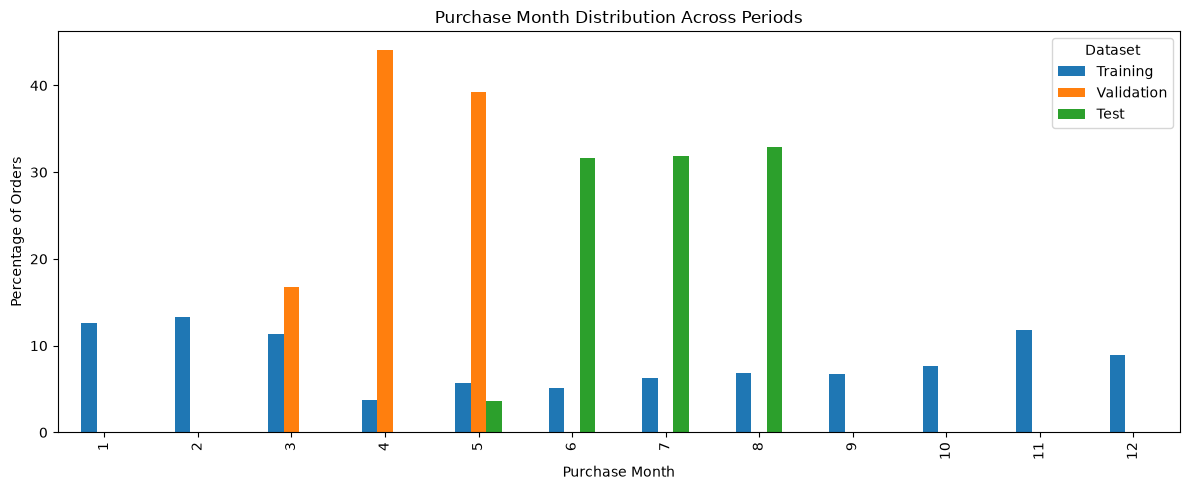

In [26]:
import matplotlib.pyplot as plt

ax = month_distribution.mul(100).plot(
    kind="bar",
    figsize=(12, 5)
)

ax.set_title("Purchase Month Distribution Across Periods")
ax.set_xlabel("Purchase Month")
ax.set_ylabel("Percentage of Orders")
ax.legend(title="Dataset")

plt.tight_layout()
plt.show()

## 5. Target Distribution Analysis

This experiment investigates changes in the
proportion of late deliveries across temporal
partitions and purchase months.

In [27]:
target_results = []

for name, df in periods.items():

    total_orders = len(df)
    late_orders = int(df["is_late"].sum())

    target_results.append({
        "Period": name,
        "Start_Date": df["order_purchase_timestamp"].min(),
        "End_Date": df["order_purchase_timestamp"].max(),
        "Total_Orders": total_orders,
        "Late_Orders": late_orders,
        "Late_Rate": late_orders / total_orders
    })

target_summary = pd.DataFrame(target_results)

target_summary["Late_Rate"] *= 100

target_summary_display = target_summary.copy()

target_summary_display["Late_Rate"] = (
    target_summary_display["Late_Rate"].round(3)
)

display(target_summary_display)

,Period,Start_Date,End_Date,Total_Orders,Late_Orders,Late_Rate
0,Training,2016-09-15 12:16:38,2018-03-20 09:15:24,61740,4828,7.820
1,Validation,2018-03-20 09:16:16,2018-05-26 18:16:57,15436,1032,6.686
2,Test,2018-05-26 18:18:03,2018-08-29 15:00:37,19294,674,3.493


In [28]:
monthly_target = []

for name, df in periods.items():

    summary = (
        df.groupby("purchase_month")["is_late"]
        .agg(
            total_orders="count",
            late_orders="sum",
            late_rate="mean"
        )
        .reset_index()
    )

    summary["Period"] = name
    monthly_target.append(summary)

monthly_target_df = pd.concat(
    monthly_target,
    ignore_index=True
)

monthly_target_df["late_rate"] *= 100

display(
    monthly_target_df.round(2)
)

,purchase_month,total_orders,late_orders,late_rate,Period
0,1,7819,425,5.44,Training
1,2,8208,975,11.88,Training
2,3,6969,1159,16.63,Training
3,4,2303,151,6.56,Training
4,5,3545,106,2.99,Training
5,6,3135,95,3.03,Training
6,7,3872,108,2.79,Training
7,8,4193,122,2.91,Training
8,9,4151,183,4.41,Training
9,10,4743,189,3.98,Training


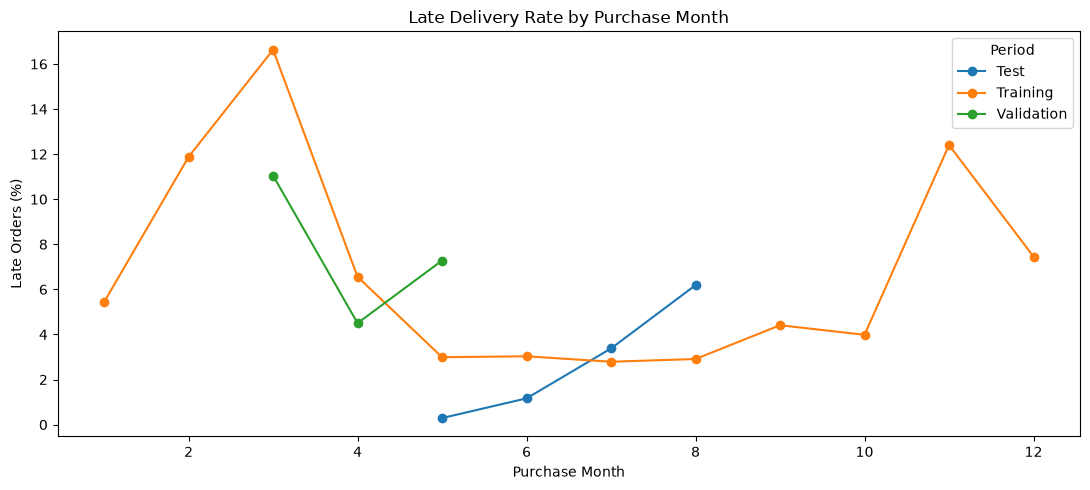

In [29]:
monthly_rates = monthly_target_df.pivot(
    index="purchase_month",
    columns="Period",
    values="late_rate"
)

ax = monthly_rates.plot(
    marker="o",
    figsize=(11, 5)
)

ax.set_title("Late Delivery Rate by Purchase Month")
ax.set_xlabel("Purchase Month")
ax.set_ylabel("Late Orders (%)")
ax.legend(title="Period")

plt.tight_layout()
plt.show()

In [30]:
monthly_timeline = []

for name, df in periods.items():

    temp = df.copy()

    temp["YearMonth"] = (
        pd.to_datetime(temp["order_purchase_timestamp"])
        .dt.to_period("M")
        .astype(str)
    )

    summary = (
        temp.groupby("YearMonth")["is_late"]
        .agg(
            total_orders="count",
            late_orders="sum",
            late_rate="mean"
        )
        .reset_index()
    )

    summary["Period"] = name

    monthly_timeline.append(summary)

monthly_timeline_df = pd.concat(
    monthly_timeline,
    ignore_index=True
)

monthly_timeline_df["late_rate"] *= 100

display(
    monthly_timeline_df.round(3)
)

,YearMonth,total_orders,late_orders,late_rate,Period
0,2016-09,1,1,100.000,Training
1,2016-10,265,2,0.755,Training
2,2016-12,1,0,0.000,Training
3,2017-01,750,22,2.933,Training
4,2017-02,1653,49,2.964,Training
5,2017-03,2546,116,4.556,Training
6,2017-04,2303,151,6.557,Training
7,2017-05,3545,106,2.990,Training
8,2017-06,3135,95,3.030,Training
9,2017-07,3872,108,2.789,Training


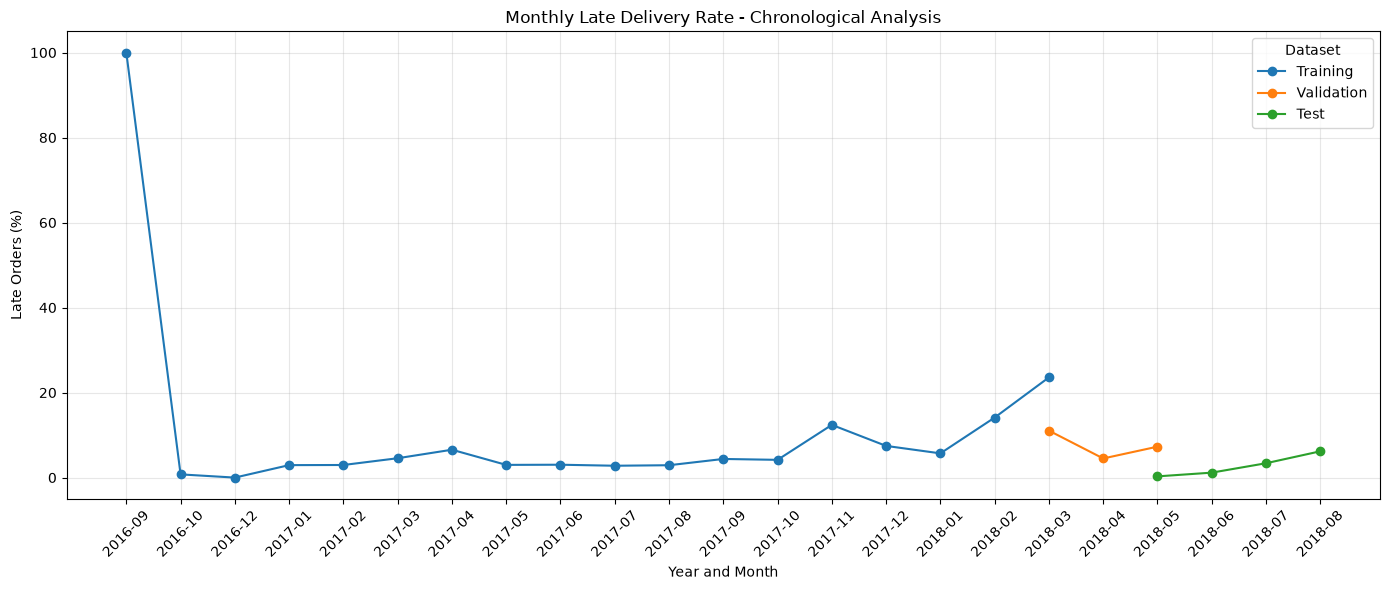

In [31]:
plt.figure(figsize=(14, 6))

for name in ["Training", "Validation", "Test"]:

    subset = monthly_timeline_df[
        monthly_timeline_df["Period"] == name
    ]

    plt.plot(
        subset["YearMonth"],
        subset["late_rate"],
        marker="o",
        label=name
    )

plt.title("Monthly Late Delivery Rate - Chronological Analysis")
plt.xlabel("Year and Month")
plt.ylabel("Late Orders (%)")
plt.xticks(rotation=45)
plt.legend(title="Dataset")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

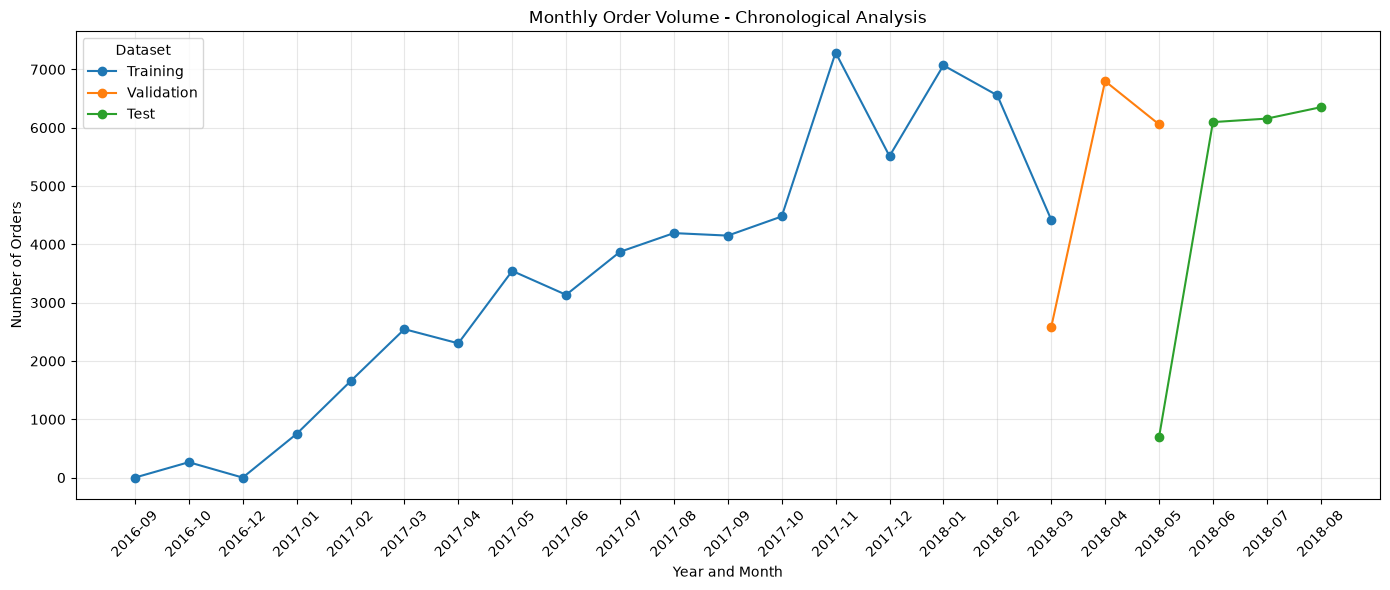

In [32]:
plt.figure(figsize=(14, 6))

for name in ["Training", "Validation", "Test"]:

    subset = monthly_timeline_df[
        monthly_timeline_df["Period"] == name
    ]

    plt.plot(
        subset["YearMonth"],
        subset["total_orders"],
        marker="o",
        label=name
    )

plt.title("Monthly Order Volume - Chronological Analysis")
plt.xlabel("Year and Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.legend(title="Dataset")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
monthly_timeline_df.to_csv(
    RESEARCH_REPORTS_DIR / "target_drift_year_month.csv",
    index=False
)

print("Análise cronológica salva com sucesso!")

Análise cronológica salva com sucesso!


## 6. Complete Monthly Timeline

This analysis combines the chronological partitions
to reconstruct the full monthly order timeline.

Vertical markers indicate the validation and test
boundaries within the complete timeline.

In [34]:
all_data = pd.concat(
    [
        splits["fit_data"],
        splits["validation_data"],
        splits["test_data"]
    ],
    ignore_index=True
)

all_data["order_purchase_timestamp"] = pd.to_datetime(
    all_data["order_purchase_timestamp"]
)

all_data["YearMonth"] = (
    all_data["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

monthly_all = (
    all_data.groupby("YearMonth")
    .agg(
        total_orders=("is_late", "count"),
        late_orders=("is_late", "sum"),
        late_rate=("is_late", "mean")
    )
    .reset_index()
)

monthly_all["late_rate"] *= 100

monthly_all["month_start"] = pd.to_datetime(
    monthly_all["YearMonth"] + "-01"
)

display(monthly_all.round(3))

C:\Users\Cauan\AppData\Local\Temp\ipykernel_11772\4291598257.py:36: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_all.round(3))


,YearMonth,total_orders,late_orders,late_rate,month_start
0,2016-09,1,1,100.000,2016-09-01
1,2016-10,265,2,0.755,2016-10-01
2,2016-12,1,0,0.000,2016-12-01
3,2017-01,750,22,2.933,2017-01-01
4,2017-02,1653,49,2.964,2017-02-01
5,2017-03,2546,116,4.556,2017-03-01
6,2017-04,2303,151,6.557,2017-04-01
7,2017-05,3545,106,2.990,2017-05-01
8,2017-06,3135,95,3.030,2017-06-01
9,2017-07,3872,108,2.789,2017-07-01


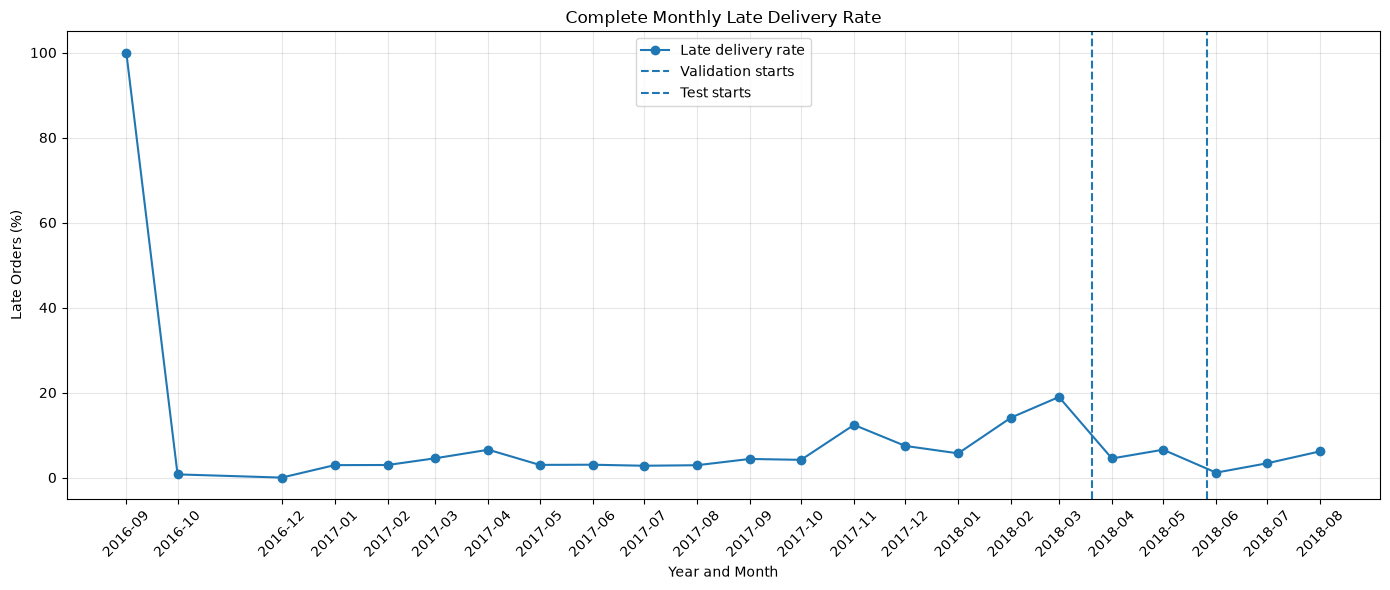

In [35]:
validation_start = pd.to_datetime(
    splits["validation_data"]["order_purchase_timestamp"].min()
)

test_start = pd.to_datetime(
    splits["test_data"]["order_purchase_timestamp"].min()
)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_all["month_start"],
    monthly_all["late_rate"],
    marker="o",
    label="Late delivery rate"
)

plt.axvline(
    validation_start,
    linestyle="--",
    label="Validation starts"
)

plt.axvline(
    test_start,
    linestyle="--",
    label="Test starts"
)

plt.title("Complete Monthly Late Delivery Rate")
plt.xlabel("Year and Month")
plt.ylabel("Late Orders (%)")
plt.xticks(
    monthly_all["month_start"],
    monthly_all["YearMonth"],
    rotation=45
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [36]:
import joblib

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

MODEL_PATH = (
    PROJECT_DIR /
    "models" /
    "delivery_delay_logistic_regression.joblib"
)

final_model = joblib.load(MODEL_PATH)

X_test = splits["X_test"].copy()
test_data = splits["test_data"].copy()

assert X_test.index.equals(test_data.index), (
    "Os índices dos dados de teste não estão alinhados."
)

THRESHOLD = 0.15

probabilities = final_model.predict_proba(X_test)[:, 1]

predictions = (
    probabilities >= THRESHOLD
).astype(int)

test_results = test_data[
    ["order_purchase_timestamp", "is_late"]
].copy()

test_results["probability"] = probabilities
test_results["predicted_is_late"] = predictions

test_results["YearMonth"] = (
    pd.to_datetime(test_results["order_purchase_timestamp"])
    .dt.to_period("M")
    .astype(str)
)

print("Modelo carregado!")
print("Previsões:", len(test_results))
print("Threshold:", THRESHOLD)

Modelo carregado!
Previsões: 19294
Threshold: 0.15


In [37]:
monthly_performance = []

for month, group in test_results.groupby("YearMonth"):

    y_true = group["is_late"]
    y_pred = group["predicted_is_late"]
    y_prob = group["probability"]

    positive_cases = int(y_true.sum())

    ap = (
        average_precision_score(y_true, y_prob)
        if positive_cases > 0
        else np.nan
    )

    late_rate = y_true.mean()

    monthly_performance.append({
        "YearMonth": month,
        "Total_Orders": len(group),
        "Late_Orders": positive_cases,
        "Late_Rate": late_rate,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1_Score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "Average_Precision": ap,
        "AP_Lift": (
            ap / late_rate
            if late_rate > 0 and not np.isnan(ap)
            else np.nan
        )
    })

monthly_performance_df = pd.DataFrame(
    monthly_performance
)

display(monthly_performance_df.round(4))

,YearMonth,Total_Orders,Late_Orders,Late_Rate,Accuracy,Precision,Recall,F1_Score,Average_Precision,AP_Lift
0,2018-05,691,2,0.0029,0.9942,0.0000,0.0000,0.0000,0.0288,9.9553
1,2018-06,6096,71,0.0116,0.9559,0.0909,0.3099,0.1406,0.0794,6.8177
2,2018-07,6156,208,0.0338,0.8169,0.0611,0.3077,0.1020,0.0691,2.0448
3,2018-08,6351,393,0.0619,0.7496,0.0679,0.2392,0.1057,0.0807,1.3037


In [38]:
monthly_performance_df.to_csv(
    RESEARCH_REPORTS_DIR /
    "monthly_model_performance_test.csv",
    index=False
)

monthly_all.to_csv(
    RESEARCH_REPORTS_DIR /
    "complete_monthly_timeline.csv",
    index=False
)

print("Relatórios cronológicos salvos!")

Relatórios cronológicos salvos!


## 7. Model Performance vs. Majority-Class Baseline

This experiment compares the Logistic Regression
classifier against a naive baseline that predicts
all deliveries as on-time.

The comparison focuses on monthly accuracy and
the trade-off between identifying late deliveries
and generating false positive alerts.

In [39]:
baseline_comparison = monthly_performance_df.copy()

baseline_comparison["Baseline_Accuracy"] = (
    1 - baseline_comparison["Late_Rate"]
)

baseline_comparison["Accuracy_Difference_pp"] = (
    baseline_comparison["Accuracy"] -
    baseline_comparison["Baseline_Accuracy"]
) * 100

baseline_comparison["Model_Better_Than_Baseline"] = (
    baseline_comparison["Accuracy"] >
    baseline_comparison["Baseline_Accuracy"]
)

display(
    baseline_comparison[[
        "YearMonth",
        "Total_Orders",
        "Late_Orders",
        "Accuracy",
        "Baseline_Accuracy",
        "Accuracy_Difference_pp",
        "Recall",
        "Average_Precision"
    ]].round(4)
)

,YearMonth,Total_Orders,Late_Orders,Accuracy,Baseline_Accuracy,Accuracy_Difference_pp,Recall,Average_Precision
0,2018-05,691,2,0.9942,0.9971,-0.2894,0.0000,0.0288
1,2018-06,6096,71,0.9559,0.9884,-3.2480,0.3099,0.0794
2,2018-07,6156,208,0.8169,0.9662,-14.9285,0.3077,0.0691
3,2018-08,6351,393,0.7496,0.9381,-18.8474,0.2392,0.0807


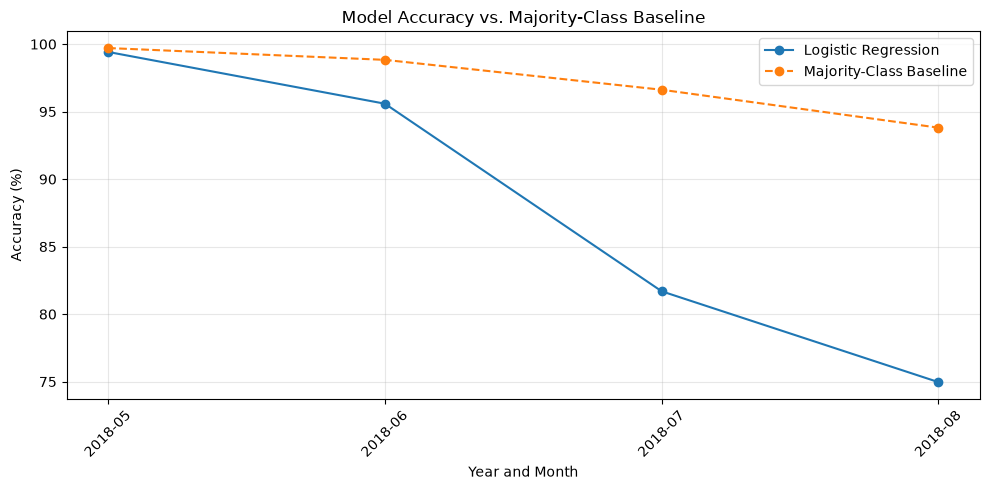

In [40]:
plt.figure(figsize=(10, 5))

plt.plot(
    baseline_comparison["YearMonth"],
    baseline_comparison["Accuracy"] * 100,
    marker="o",
    label="Logistic Regression"
)

plt.plot(
    baseline_comparison["YearMonth"],
    baseline_comparison["Baseline_Accuracy"] * 100,
    marker="o",
    linestyle="--",
    label="Majority-Class Baseline"
)

plt.title("Model Accuracy vs. Majority-Class Baseline")
plt.xlabel("Year and Month")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [41]:
baseline_comparison.to_csv(
    RESEARCH_REPORTS_DIR /
    "monthly_baseline_comparison.csv",
    index=False
)

print("Comparação com baseline salva!")

Comparação com baseline salva!


## 8. Monthly Confusion Matrix Analysis

This experiment analyzes monthly false positives,
false negatives, true positives, and true negatives.

It also compares the actual late delivery rate
with the model's predicted late delivery rate.

In [42]:
from sklearn.metrics import confusion_matrix

monthly_errors = []

for month, group in test_results.groupby("YearMonth"):

    y_true = group["is_late"]
    y_pred = group["predicted_is_late"]
    y_prob = group["probability"]

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    monthly_errors.append({
        "YearMonth": month,
        "Total_Orders": len(group),
        "Actual_Late": int(y_true.sum()),
        "Predicted_Late": int(y_pred.sum()),
        "True_Positive": int(tp),
        "False_Positive": int(fp),
        "True_Negative": int(tn),
        "False_Negative": int(fn),
        "Actual_Late_Rate": y_true.mean(),
        "Predicted_Late_Rate": y_pred.mean()
    })

monthly_errors_df = pd.DataFrame(monthly_errors)

monthly_errors_df["Actual_Late_Rate"] *= 100
monthly_errors_df["Predicted_Late_Rate"] *= 100

display(monthly_errors_df.round(3))

,YearMonth,Total_Orders,Actual_Late,Predicted_Late,True_Positive,False_Positive,True_Negative,False_Negative,Actual_Late_Rate,Predicted_Late_Rate
0,2018-05,691,2,2,0,2,687,2,0.289,0.289
1,2018-06,6096,71,242,22,220,5805,49,1.165,3.970
2,2018-07,6156,208,1047,64,983,4965,144,3.379,17.008
3,2018-08,6351,393,1385,94,1291,4667,299,6.188,21.808


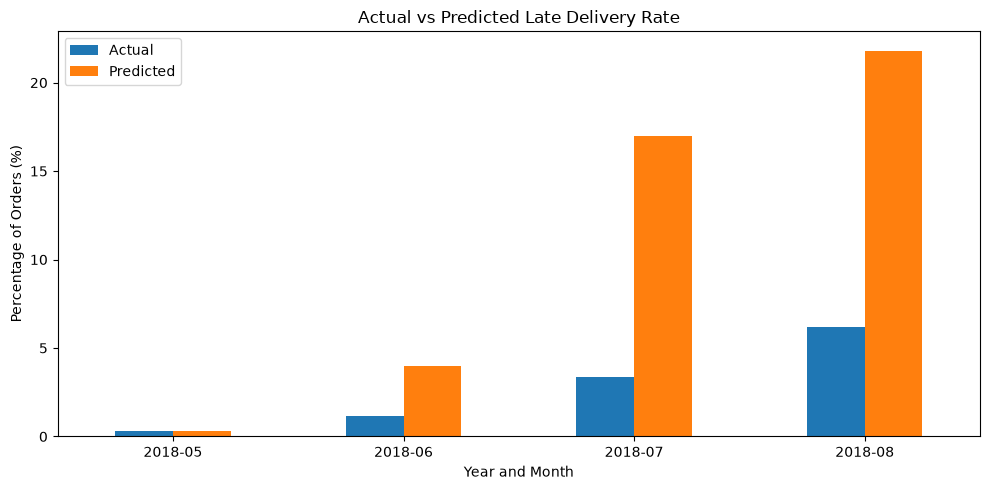

In [43]:
alert_comparison = monthly_errors_df.set_index("YearMonth")[
    ["Actual_Late_Rate", "Predicted_Late_Rate"]
]

ax = alert_comparison.plot(
    kind="bar",
    figsize=(10, 5)
)

ax.set_title("Actual vs Predicted Late Delivery Rate")
ax.set_xlabel("Year and Month")
ax.set_ylabel("Percentage of Orders (%)")
ax.legend(["Actual", "Predicted"])

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [44]:
monthly_errors_df.to_csv(
    RESEARCH_REPORTS_DIR / "monthly_confusion_analysis.csv",
    index=False
)

print("Análise dos erros salva!")

Análise dos erros salva!


## 9. Prediction Probability Calibration

This experiment investigates whether predicted
delivery delay probabilities are consistent with
observed late delivery frequencies.

The analysis includes monthly mean predicted
probabilities and Brier scores.

In [45]:
calibration_results = []

for month, group in test_results.groupby("YearMonth"):

    actual_rate = group["is_late"].mean()

    mean_probability = group["probability"].mean()

    calibration_results.append({
        "YearMonth": month,
        "Total_Orders": len(group),
        "Actual_Late_Rate": actual_rate,
        "Mean_Predicted_Probability": mean_probability,
        "Calibration_Difference": (
            mean_probability - actual_rate
        )
    })

calibration_df = pd.DataFrame(calibration_results)

calibration_df[
    [
        "Actual_Late_Rate",
        "Mean_Predicted_Probability",
        "Calibration_Difference"
    ]
] *= 100

display(calibration_df.round(3))

,YearMonth,Total_Orders,Actual_Late_Rate,Mean_Predicted_Probability,Calibration_Difference
0,2018-05,691,0.289,2.655,2.365
1,2018-06,6096,1.165,5.362,4.197
2,2018-07,6156,3.379,9.704,6.325
3,2018-08,6351,6.188,11.376,5.188


In [46]:
from sklearn.metrics import brier_score_loss

brier_results = []

training_prevalence = splits["y_fit"].mean()

for month, group in test_results.groupby("YearMonth"):

    y_true = group["is_late"]
    y_prob = group["probability"]

    model_brier = brier_score_loss(
        y_true,
        y_prob
    )

    baseline_brier = brier_score_loss(
        y_true,
        np.full(len(y_true), training_prevalence)
    )

    brier_results.append({
        "YearMonth": month,
        "Model_Brier": model_brier,
        "Training_Prevalence_Baseline_Brier": baseline_brier
    })

brier_df = pd.DataFrame(brier_results)

display(brier_df.round(5))

,YearMonth,Model_Brier,Training_Prevalence_Baseline_Brier
0,2018-05,0.00364,0.00856
1,2018-06,0.01354,0.01594
2,2018-07,0.03918,0.03462
3,2018-08,0.06408,0.05832


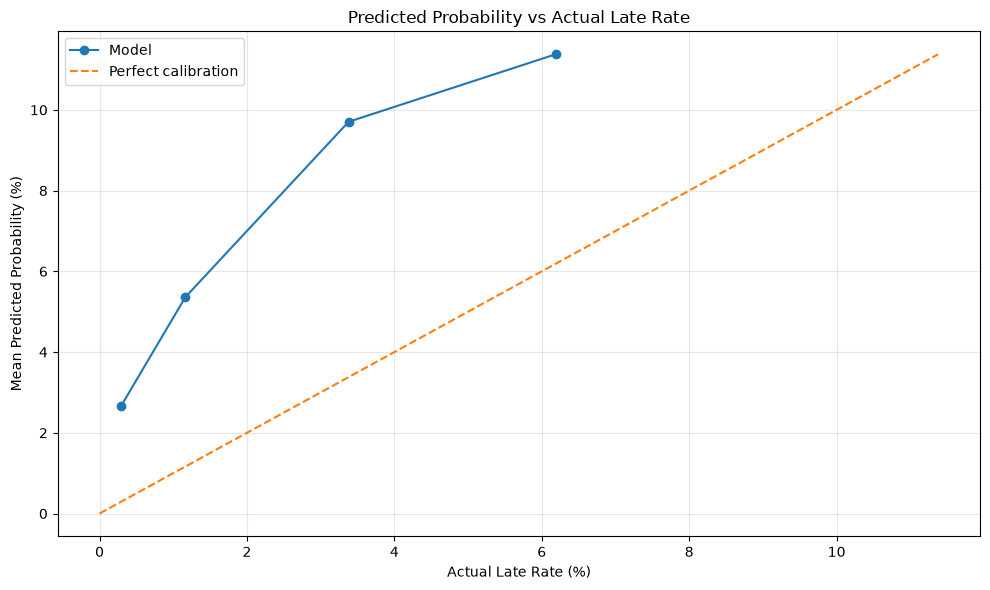

In [47]:
plt.figure(figsize=(10, 6))

plt.plot(
    calibration_df["Actual_Late_Rate"],
    calibration_df["Mean_Predicted_Probability"],
    marker="o",
    label="Model"
)

max_value = max(
    calibration_df["Actual_Late_Rate"].max(),
    calibration_df["Mean_Predicted_Probability"].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--",
    label="Perfect calibration"
)

plt.title("Predicted Probability vs Actual Late Rate")
plt.xlabel("Actual Late Rate (%)")
plt.ylabel("Mean Predicted Probability (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [48]:
calibration_df.to_csv(
    RESEARCH_REPORTS_DIR / "monthly_calibration.csv",
    index=False
)

brier_df.to_csv(
    RESEARCH_REPORTS_DIR / "monthly_brier_scores.csv",
    index=False
)

print("Relatórios de calibração salvos!")

Relatórios de calibração salvos!


In [49]:
from sklearn.metrics import confusion_matrix

for month, group in test_results.groupby("YearMonth"):

    tn, fp, fn, tp = confusion_matrix(
        group["is_late"],
        group["predicted_is_late"],
        labels=[0, 1]
    ).ravel()

    print(f"\nMês: {month}")
    print(f"TN: {tn}")
    print(f"FP: {fp}")
    print(f"FN: {fn}")
    print(f"TP: {tp}")

    print(
        "Total:",
        tn + fp + fn + tp
    )

    print(
        "Precisão:",
        round(tp / (tp + fp), 4)
        if tp + fp > 0 else 0
    )

    print(
        "Recall:",
        round(tp / (tp + fn), 4)
        if tp + fn > 0 else 0
    )


Mês: 2018-05
TN: 687
FP: 2
FN: 2
TP: 0
Total: 691
Precisão: 0.0
Recall: 0.0

Mês: 2018-06
TN: 5805
FP: 220
FN: 49
TP: 22
Total: 6096
Precisão: 0.0909
Recall: 0.3099

Mês: 2018-07
TN: 4965
FP: 983
FN: 144
TP: 64
Total: 6156
Precisão: 0.0611
Recall: 0.3077

Mês: 2018-08
TN: 4667
FP: 1291
FN: 299
TP: 94
Total: 6351
Precisão: 0.0679
Recall: 0.2392


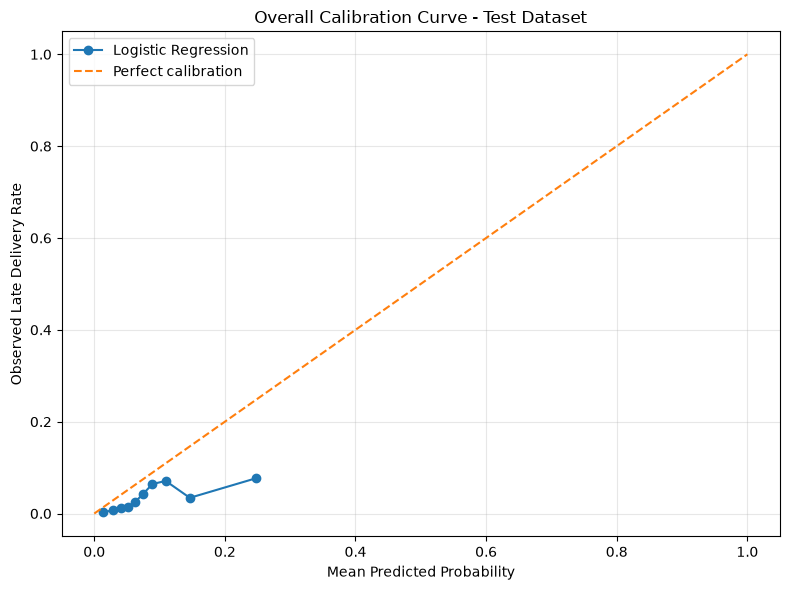

In [50]:
from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(
    test_results["is_late"],
    test_results["probability"],
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(8, 6))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.title("Overall Calibration Curve - Test Dataset")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Late Delivery Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [51]:
from sklearn.metrics import brier_score_loss

y_test = test_results["is_late"]
p_test = test_results["probability"]

training_prevalence = splits["y_fit"].mean()
test_prevalence = y_test.mean()

brier_model = brier_score_loss(y_test, p_test)

brier_training_baseline = brier_score_loss(
    y_test,
    np.full(len(y_test), training_prevalence)
)

brier_test_baseline = brier_score_loss(
    y_test,
    np.full(len(y_test), test_prevalence)
)

print("Brier Score - Modelo:", round(brier_model, 5))
print("Baseline - Prevalência do treinamento:",
      round(brier_training_baseline, 5))
print("Baseline - Prevalência do teste:",
      round(brier_test_baseline, 5))

print(
    "\nBrier Skill Score:",
    round(1 - brier_model / brier_training_baseline, 4)
)

Brier Score - Modelo: 0.038
Baseline - Prevalência do treinamento: 0.03558
Baseline - Prevalência do teste: 0.03371

Brier Skill Score: -0.068
